# Data Exploration Notebook

The goal of this notebook is to explore the given data ahead of the modeling task

## The task

The goal of the task is to perform binary classification. We should predict for each person whether they have coronoary heart disease (MICHD) from their answers to a health survey. Our target variable is **_MICHD**: it takes two values: either +1 if the respondant was told by a health professional that they had a heart attack (myocardial infection), angina or coronary heart disease or -1 otherwise

**Input and Output:** We have a training set of 328135 people x 321 features with labels. The test set contains 109379 people without the labels. We submit one prediction {-1, 1} per test ID as a CSV file on AIcrowd. For more details on the rules of submission and the expected deliverables, please check the project description 

## The Dataset

The [Behavioral Risk Factor Surveillance System (BRFSS) 2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) is a US telephone survey about health behaviour. Each row corresponds to one person and each column represents either a raw survey answer or a variable calculated by CDC for those answers. The codebook on the official page defines every column and every value code.  We have the following files given

| File | Rows | Columns | Content |
|---|---|---|---|
| `x_train.csv` | 328,135 | `Id` + 321 features | training features |
| `y_train.csv` | 328,135 | `Id`, `_MICHD` | label in {−1, +1} |
| `x_test.csv` | 109,379 | `Id` + 321 features | test features (same columns) |
| `sample_submission.csv` | 109,379 | `Id`, `Prediction` | submission format (all −1) |

**Column names follow the BRFSS codebook**
- No prefix (`GENHLTH`, `SMOKE100`, …): the raw answer to one survey question.
- Leading underscore (`_AGEG5YR`, `_BMI5`, `_SMOKER3`, …) or trailing underscore (`MAXVO2_`, `FRUTDA1_`, …): **calculated variables**, i.e. cleaned, recoded or combined versions of raw answers. They are often the easiest columns to use.
- Columns are in questionnaire order, so neighbouring columns belong to the same topic (section 6 groups them).

**How values are coded.** Every value is a number. Empty fields (NaN) mostly mean "question not asked". The main conventions:

| Code | Meaning | Example |
|---|---|---|
| `1` / `2` | Yes / No | `CVDSTRK3` (ever had a stroke) |
| `7`, `77`, `777`, `7777` | Don't know / not sure | `GENHLTH = 7` |
| `9`, `99`, `999`, `9999` | Refused (in calculated variables: "don't know, refused or missing") | `INCOME2 = 99` |
| `8`, `88`, `888` | None / never: **a real answer, often meaning 0** | `PHYSHLTH = 88` → 0 bad days |
| `555` | Never | `FRUIT1 = 555` |
| `1xx` / `2xx` | xx per week / xx per month | `ALCDAY5 = 203` → 3 days per month |
| `9xxx` | value given in metric units | `WEIGHT2 = 9070` → 70 kg |

These codes are **not universal**: in `EMPLOY1`, `7` means *retired*, and some calculated variables use their own codes (`_AGEG5YR = 14`, `_DRNKWEK = 99900`).
Check the codebook for every feature you rely on.

## Exploring the Dataset

In [1]:
import sys
from pathlib import Path 

import numpy as np
import matplotlib.pyplot as plt 

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from helpers import load_csv_data
import time
import os

In [2]:
data_dir = f"{ROOT}/data"

In [3]:
start = time.time()
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)
end = time.time()
print(f"Loaded in {end-start} seconds")
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| y_train:", y_train.shape)

Loaded in 30.274393796920776 seconds
x_train: (328135, 321) | x_test: (109379, 321) | y_train: (328135,)


In [4]:
# getting the feature names since load_csv_data drops the header 
with open(os.path.join(data_dir, "x_train.csv")) as train_data_reader: 
    header = train_data_reader.readline().strip().split(",")

feature_names = np.array(header[1:])
print(f"In total we have {len(feature_names)} features")
print(f"Some sample features are {feature_names[:5]}")

# name to column index mapping
name_column_index_mapping = {name: j for j, name in enumerate(feature_names)}

with open(os.path.join(data_dir, "x_test.csv")) as test_data_reader: 
    header_test = test_data_reader.readline().strip().split(",")

assert header == header_test, "train and test columns differ"
assert len(feature_names) == x_train.shape[1] == x_test.shape[1], "names do not match the data"

In total we have 321 features
Some sample features are ['_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY']


In [5]:
# How many variables were recorded and how many were calculated on what was recorded? 
# we got the following infromation from the CDC official documentation
derived_without_underscore = {"HTIN4", "HTM4", "WTKG3", "DRNKANY5"} 
not_derived_with_underscore = {"_STATE"}

def is_calculated(name): 
    if name in not_derived_with_underscore: 
        return False
    return name.startswith("_") or name.endswith("_") or name in derived_without_underscore

calculated_features = np.array([is_calculated(n) for n in feature_names])
print(f"In total we have {calculated_features.sum()} calculated features and {(~calculated_features).sum()} recorded features") 

In total we have 103 calculated features and 218 recorded features


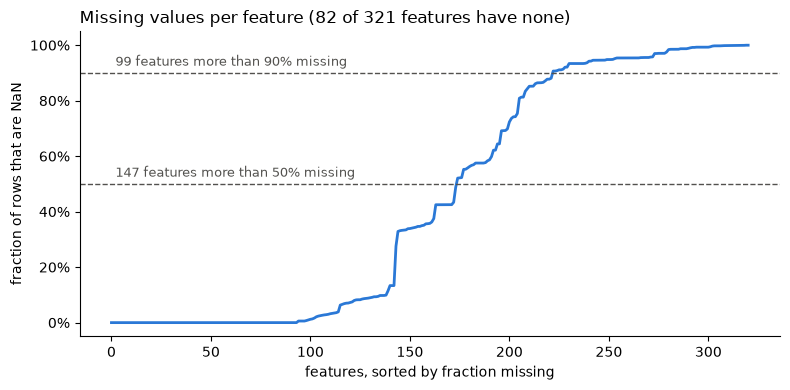

In [6]:
from matplotlib.ticker import PercentFormatter

missing_fraction = np.isnan(x_train).mean(axis=0)       # one value per feature
order = np.argsort(missing_fraction)                     # least to most missing

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(len(order)), missing_fraction[order], color="#2a78d6", lw=2)

# reference lines with the number of features above each threshold
for threshold in [0.5, 0.9]:
    n_above = (missing_fraction > threshold).sum()
    ax.axhline(threshold, color="#52514e", ls="--", lw=1)
    ax.text(2, threshold + 0.015, f"{n_above} features more than {threshold:.0%} missing",
            color="#52514e", fontsize=9, va="bottom")

ax.set_xlabel("features, sorted by fraction missing")
ax.set_ylabel("fraction of rows that are NaN")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title(f"Missing values per feature ({(missing_fraction == 0).sum()} of {len(feature_names)} features have none)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

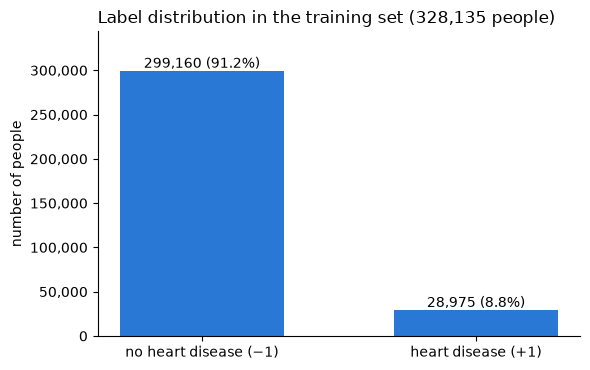

In [7]:
from matplotlib.ticker import StrMethodFormatter

values, counts = np.unique(y_train, return_counts=True)        # values = [-1, 1]
names = {-1: "no heart disease (−1)", 1: "heart disease (+1)"}

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar([names[v] for v in values], counts, width=0.6, color="#2a78d6")

# write the count and share on top of each bar
for bar, n in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,} ({n / len(y_train):.1%})",
            ha="center", va="bottom", fontsize=10)

ax.set_ylabel("number of people")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))   # 300,000 instead of 300000
ax.set_title(f"Label distribution in the training set ({len(y_train):,} people)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, counts.max() * 1.15)    # leave room for the labels above the bars
plt.tight_layout()
plt.show()

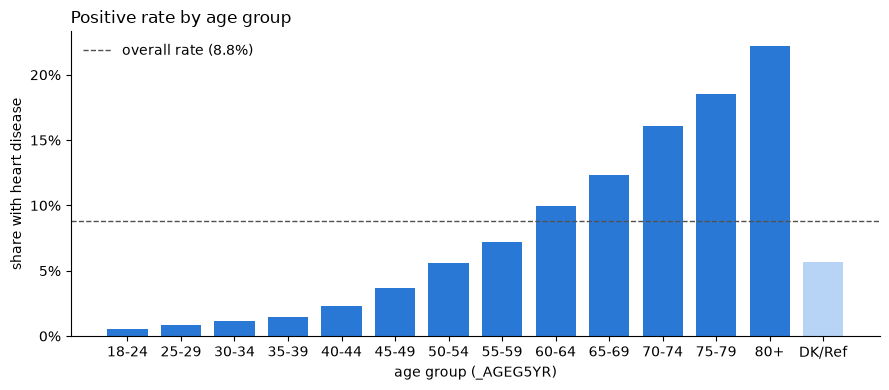

  18-24:   0.5%  (n = 18,145)
  25-29:   0.9%  (n = 14,686)
  30-34:   1.1%  (n = 17,122)
  35-39:   1.5%  (n = 18,308)
  40-44:   2.3%  (n = 19,296)
  45-49:   3.7%  (n = 22,539)
  50-54:   5.6%  (n = 29,693)
  55-59:   7.2%  (n = 34,379)
  60-64:  10.0%  (n = 37,210)
  65-69:  12.3%  (n = 36,665)
  70-74:  16.1%  (n = 28,190)
  75-79:  18.5%  (n = 20,893)
    80+:  22.2%  (n = 27,066)
 DK/Ref:   5.7%  (n = 3,943)


In [8]:
from matplotlib.ticker import PercentFormatter

AGE_GROUPS = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
              8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+", 14: "DK/Ref"}

age = x_train[:, name_column_index_mapping["_AGEG5YR"]]
y01 = (y_train == 1).astype(int)                         # 1 = heart disease, 0 = not

groups = np.unique(age)                                  # 1 ... 14 (no NaN in this column)
positive_rate = np.array([y01[age == g].mean() for g in groups])
group_size = np.array([(age == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#b7d3f6" if g == 14 else "#2a78d6" for g in groups]   # lighter: "don't know / refused"
ax.bar([AGE_GROUPS[g] for g in groups], positive_rate, width=0.75, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

ax.set_xlabel("age group (_AGEG5YR)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Positive rate by age group", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for g, r, n in zip(groups, positive_rate, group_size):
    print(f"{AGE_GROUPS[g]:>7}: {r:6.1%}  (n = {n:,})")

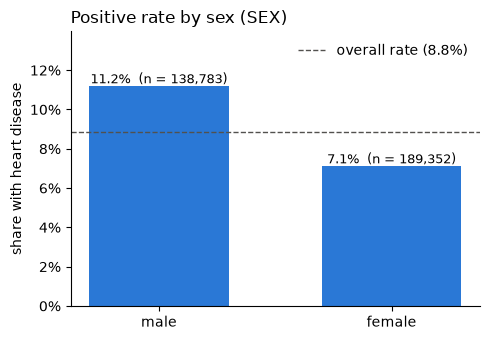

In [9]:
from matplotlib.ticker import PercentFormatter

SEXES = {1: "male", 2: "female"}

sex = x_train[:, name_column_index_mapping["SEX"]]
groups = np.unique(sex)                                  # 1, 2 (no NaN or codes in this column)
positive_rate = np.array([y01[sex == g].mean() for g in groups])
group_size = np.array([(sex == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar([SEXES[g] for g in groups], positive_rate, width=0.6, color="#2a78d6")
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the rate and group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"{r:.1%}  (n = {n:,})",
            ha="center", va="bottom", fontsize=9)

ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, positive_rate.max() * 1.25)
ax.set_title("Positive rate by sex (SEX)", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

rows with NaN (left out): 2


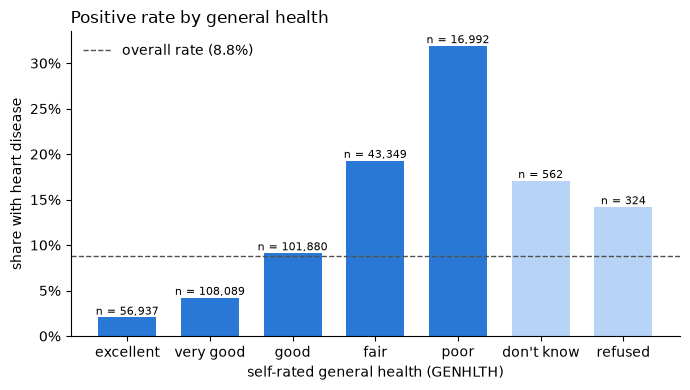

 excellent:   2.1%  (n = 56,937)
 very good:   4.2%  (n = 108,089)
      good:   9.1%  (n = 101,880)
      fair:  19.3%  (n = 43,349)
      poor:  31.9%  (n = 16,992)
don't know:  17.1%  (n = 562)
   refused:  14.2%  (n = 324)


In [10]:
from matplotlib.ticker import PercentFormatter

GENERAL_HEALTH = {1: "excellent", 2: "very good", 3: "good", 4: "fair", 5: "poor",
                  7: "don't know", 9: "refused"}

health = x_train[:, name_column_index_mapping["GENHLTH"]]
print(f"rows with NaN (left out): {np.isnan(health).sum()}")

groups = np.unique(health[~np.isnan(health)])            # 1-5, 7, 9
positive_rate = np.array([y01[health == g].mean() for g in groups])
group_size = np.array([(health == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#b7d3f6" if g in (7, 9) else "#2a78d6" for g in groups]   # lighter: non-answers
bars = ax.bar([GENERAL_HEALTH[g] for g in groups], positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("self-rated general health (GENHLTH)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Positive rate by general health", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for g, r, n in zip(groups, positive_rate, group_size):
    print(f"{GENERAL_HEALTH[g]:>10}: {r:6.1%}  (n = {n:,})")

rows with NaN (left out): 0


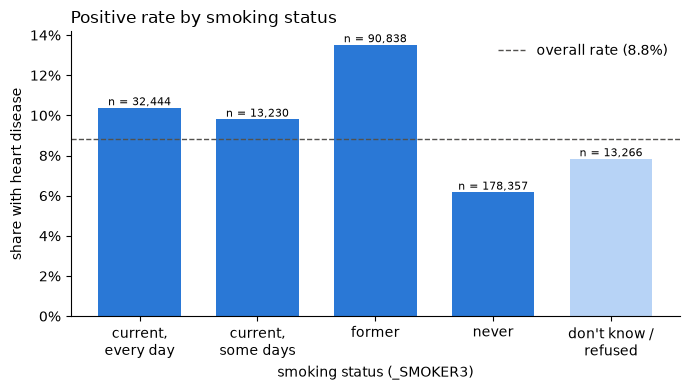

   current, every day:  10.4%  (n = 32,444)
   current, some days:   9.8%  (n = 13,230)
               former:  13.5%  (n = 90,838)
                never:   6.2%  (n = 178,357)
 don't know / refused:   7.8%  (n = 13,266)


In [11]:
from matplotlib.ticker import PercentFormatter

SMOKING_STATUS = {1: "current,\nevery day", 2: "current,\nsome days", 3: "former",
                  4: "never", 9: "don't know /\nrefused"}

smoking = x_train[:, name_column_index_mapping["_SMOKER3"]]
print(f"rows with NaN (left out): {np.isnan(smoking).sum()}")

groups = np.unique(smoking[~np.isnan(smoking)])          # 1-4, 9
positive_rate = np.array([y01[smoking == g].mean() for g in groups])
group_size = np.array([(smoking == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#b7d3f6" if g == 9 else "#2a78d6" for g in groups]    # lighter: non-answers
bars = ax.bar([SMOKING_STATUS[g] for g in groups], positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("smoking status (_SMOKER3)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Positive rate by smoking status", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for g, r, n in zip(groups, positive_rate, group_size):
    label = SMOKING_STATUS[g].replace("\n", " ")
    print(f"{label:>21}: {r:6.1%}  (n = {n:,})")

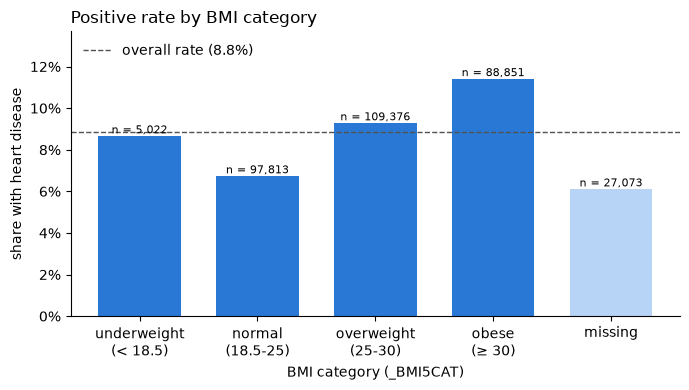

   underweight (< 18.5):   8.7%  (n = 5,022)
       normal (18.5-25):   6.7%  (n = 97,813)
     overweight (25-30):   9.3%  (n = 109,376)
           obese (≥ 30):  11.4%  (n = 88,851)
                missing:   6.1%  (n = 27,073)


In [12]:
from matplotlib.ticker import PercentFormatter

BMI_CATEGORIES = {1: "underweight\n(< 18.5)", 2: "normal\n(18.5-25)", 3: "overweight\n(25-30)",
                  4: "obese\n(≥ 30)"}

bmi_cat = x_train[:, name_column_index_mapping["_BMI5CAT"]]
bmi_missing = np.isnan(bmi_cat)                          # weight or height not reported

groups = np.unique(bmi_cat[~bmi_missing])                # 1-4
labels = [BMI_CATEGORIES[g] for g in groups] + ["missing"]
positive_rate = np.array([y01[bmi_cat == g].mean() for g in groups] + [y01[bmi_missing].mean()])
group_size = np.array([(bmi_cat == g).sum() for g in groups] + [bmi_missing.sum()])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#2a78d6"] * len(groups) + ["#b7d3f6"]         # lighter: missing
bars = ax.bar(labels, positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("BMI category (_BMI5CAT)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, positive_rate.max() * 1.2)
ax.set_title("Positive rate by BMI category", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for label, r, n in zip(labels, positive_rate, group_size):
    print(f"{label.replace(chr(10), ' '):>23}: {r:6.1%}  (n = {n:,})")

rows with NaN (left out): 1


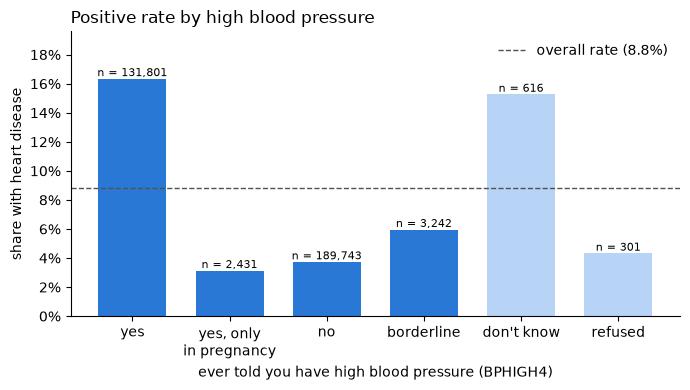

                   yes:  16.3%  (n = 131,801)
yes, only in pregnancy:   3.1%  (n = 2,431)
                    no:   3.7%  (n = 189,743)
            borderline:   6.0%  (n = 3,242)
            don't know:  15.3%  (n = 616)
               refused:   4.3%  (n = 301)


In [13]:
from matplotlib.ticker import MaxNLocator, PercentFormatter

BLOOD_PRESSURE = {1: "yes", 2: "yes, only\nin pregnancy", 3: "no", 4: "borderline", 7: "don't know", 9: "refused"}

blood_pressure = x_train[:, name_column_index_mapping["BPHIGH4"]]
print(f"rows with NaN (left out): {np.isnan(blood_pressure).sum()}")

groups = np.unique(blood_pressure[~np.isnan(blood_pressure)])   # 1-4, 7, 9
positive_rate = np.array([y01[blood_pressure == g].mean() for g in groups])
group_size = np.array([(blood_pressure == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#b7d3f6" if g in (7, 9) else "#2a78d6" for g in groups]   # lighter: non-answers
bars = ax.bar([BLOOD_PRESSURE[g] for g in groups], positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("ever told you have high blood pressure (BPHIGH4)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))   # ticks at round percentages
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, positive_rate.max() * 1.2)
ax.set_title("Positive rate by high blood pressure", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for g, r, n in zip(groups, positive_rate, group_size):
    print(f"{BLOOD_PRESSURE[g].replace(chr(10), ' '):>22}: {r:6.1%}  (n = {n:,})")

rows with NaN (left out): 5


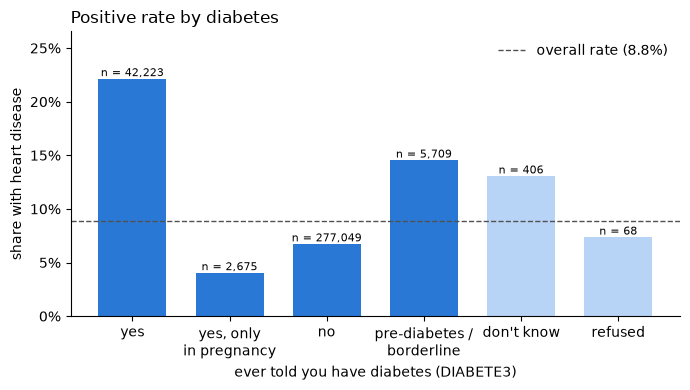

                       yes:  22.1%  (n = 42,223)
    yes, only in pregnancy:   4.0%  (n = 2,675)
                        no:   6.7%  (n = 277,049)
 pre-diabetes / borderline:  14.5%  (n = 5,709)
                don't know:  13.1%  (n = 406)
                   refused:   7.4%  (n = 68)


In [14]:
from matplotlib.ticker import MaxNLocator, PercentFormatter

DIABETES = {1: "yes", 2: "yes, only\nin pregnancy", 3: "no", 4: "pre-diabetes /\nborderline",
            7: "don't know", 9: "refused"}

diabetes = x_train[:, name_column_index_mapping["DIABETE3"]]
print(f"rows with NaN (left out): {np.isnan(diabetes).sum()}")

groups = np.unique(diabetes[~np.isnan(diabetes)])        # 1-4, 7, 9
positive_rate = np.array([y01[diabetes == g].mean() for g in groups])
group_size = np.array([(diabetes == g).sum() for g in groups])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#b7d3f6" if g in (7, 9) else "#2a78d6" for g in groups]   # lighter: non-answers
bars = ax.bar([DIABETES[g] for g in groups], positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("ever told you have diabetes (DIABETE3)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))   # ticks at round percentages
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, positive_rate.max() * 1.2)
ax.set_title("Positive rate by diabetes", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for g, r, n in zip(groups, positive_rate, group_size):
    print(f"{DIABETES[g].replace(chr(10), ' '):>26}: {r:6.1%}  (n = {n:,})")

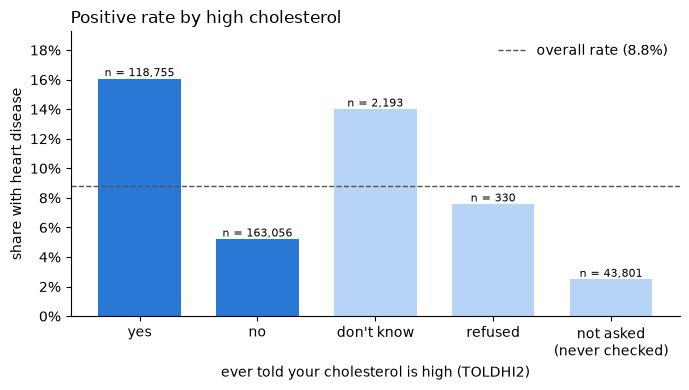

                       yes:  16.1%  (n = 118,755)
                        no:   5.2%  (n = 163,056)
                don't know:  14.0%  (n = 2,193)
                   refused:   7.6%  (n = 330)
 not asked (never checked):   2.5%  (n = 43,801)


In [15]:
from matplotlib.ticker import MaxNLocator, PercentFormatter

CHOLESTEROL = {1: "yes", 2: "no", 7: "don't know", 9: "refused"}

cholesterol = x_train[:, name_column_index_mapping["TOLDHI2"]]
not_asked = np.isnan(cholesterol)        # skip pattern: asked only if cholesterol was ever checked

groups = np.unique(cholesterol[~not_asked])              # 1, 2, 7, 9
labels = [CHOLESTEROL[g] for g in groups] + ["not asked\n(never checked)"]
positive_rate = np.array([y01[cholesterol == g].mean() for g in groups] + [y01[not_asked].mean()])
group_size = np.array([(cholesterol == g).sum() for g in groups] + [not_asked.sum()])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#b7d3f6" if g in (7, 9) else "#2a78d6" for g in groups] + ["#b7d3f6"]   # lighter: non-answers
bars = ax.bar(labels, positive_rate, width=0.7, color=colors)
ax.axhline(y01.mean(), color="#52514e", ls="--", lw=1, label=f"overall rate ({y01.mean():.1%})")

# write the group size on top of each bar
for bar, r, n in zip(bars, positive_rate, group_size):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"n = {n:,}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("ever told your cholesterol is high (TOLDHI2)")
ax.set_ylabel("share with heart disease")
ax.yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))   # ticks at round percentages
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, positive_rate.max() * 1.2)
ax.set_title("Positive rate by high cholesterol", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for label, r, n in zip(labels, positive_rate, group_size):
    print(f"{label.replace(chr(10), ' '):>26}: {r:6.1%}  (n = {n:,})")